In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [3]:
df = pd.read_csv('../data/features.csv')
x = df.drop(columns=['label']).values
y = df['label'].values

print(f'X shape: {x.shape}')
print(f'Y shape: {y.shape}')
print(f'Spam: {y.sum()} Legit: {(y == 0).sum()}')

X shape: (5572, 6)
Y shape: (5572,)
Spam: 747 Legit: 4825


In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print(f'Train: {x_train.shape} | Test: {x_test.shape}')
print(f'Train spam: {y_train.sum()} | Train legit: {(y_train == 0).sum()}')

Train: (4457, 6) | Test: (1115, 6)
Train spam: 598 | Train legit: 3859


In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y_true, y_pred, weights, w):
    n = len(y_true)
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
    loss = -np.mean(weights * (y_true * np.log(y_pred) +
                               (1 - y_true) * np.log(1 - y_pred)))
    return loss

def compute_gradients(x, y_true, y_pred, weights):
    n = len(y_true)
    error = (y_pred - y_true) * weights
    dw = (1/n) * x.T @ error
    db = (1/n) * np.sum(error)
    return dw, db

print('Function defined and testing')
print(f'Sigmoid(0) = {sigmoid(0):.4f}')
print(f'Sigmoid(100) = {sigmoid(100):.4f}')
print(f'Sigmoid(-100) = {sigmoid(-100):.4f}')

Function defined and testing
Sigmoid(0) = 0.5000
Sigmoid(100) = 1.0000
Sigmoid(-100) = 0.0000


In [11]:
n_total = len(y_train)
n_spam = y_train.sum()
n_legit = (y_train == 0).sum()

weight_spam = n_total / (2 * n_spam)
weight_legit = n_total / (2 * n_legit)

sample_weights = np.where(y_train == 1, weight_spam, weight_legit)

print(f'Weight for spam: {weight_spam:.3f}')
print(f'Weight for Legit: {weight_legit:.3f}')

Weight for spam: 3.727
Weight for Legit: 0.577


In [13]:
def train_logistic_regression(x, y, weights,learning_rate=0.01, epochs=1000):
    n_features = x.shape[1]
    w = np.zeros(n_features)
    b = 0.0
    loss_history = []

    for epoch in range(epochs):
        z = x @ w + b
        y_pred = sigmoid(z)

        loss = compute_loss(y, y_pred, weights, w)
        loss_history.append(loss)

        dw, db = compute_gradients(x, y, y_pred, weights)

        w -= learning_rate * dw
        b -= learning_rate * db

        if(epoch + 1) % 100 == 0:
            preds = (y_pred >= 0.5).astype(int)
            acc = accuracy_score(y, preds)
            print(f'Epoch {epoch + 1:4d} | Loss: {loss:.4f} | train accuracy: {acc * 100:.2f}%')
    return w, b, loss_history

print('Training function ready.')
        

Training function ready.


In [15]:
print('Training Logistic Regression')

w, b, loss_history = train_logistic_regression(
    x_train, y_train, sample_weights,
    learning_rate=0.01,
    epochs=1000
)

z_test = x_test @ w + b
y_prob = sigmoid(z_test)
y_pred = (y_prob >= 0.5).astype(int)
test_acc = accuracy_score(y_test, y_pred)

print(f'Test Accuracy: {test_acc*100:.2f}%')

Training Logistic Regression
Epoch  100 | Loss: 0.4188 | train accuracy: 86.34%
Epoch  200 | Loss: 0.3517 | train accuracy: 88.83%
Epoch  300 | Loss: 0.3148 | train accuracy: 90.31%
Epoch  400 | Loss: 0.2899 | train accuracy: 91.68%
Epoch  500 | Loss: 0.2715 | train accuracy: 92.78%
Epoch  600 | Loss: 0.2573 | train accuracy: 93.49%
Epoch  700 | Loss: 0.2459 | train accuracy: 93.87%
Epoch  800 | Loss: 0.2367 | train accuracy: 94.28%
Epoch  900 | Loss: 0.2291 | train accuracy: 94.64%
Epoch 1000 | Loss: 0.2227 | train accuracy: 94.86%
Test Accuracy: 94.08%


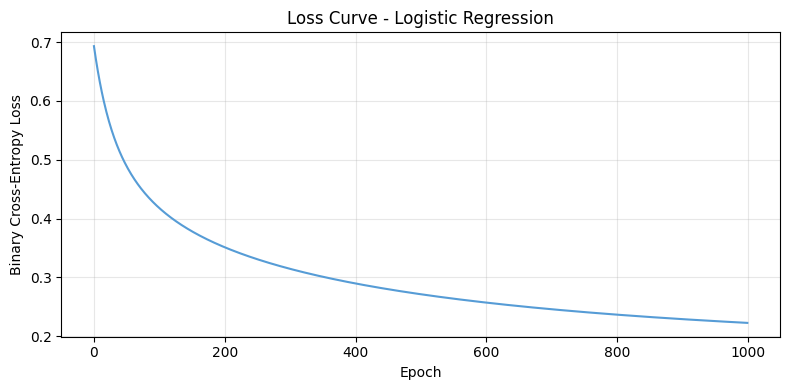

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='#569CD6', linewidth=1.5)
plt.title('Loss Curve - Logistic Regression')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/loss_curve.png')
plt.show()


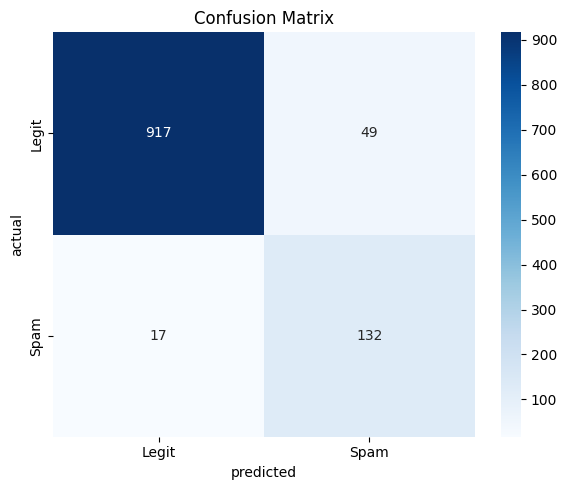

Classification Report
              precision    recall  f1-score   support

       Legit       0.98      0.95      0.97       966
        Spam       0.73      0.89      0.80       149

    accuracy                           0.94      1115
   macro avg       0.86      0.92      0.88      1115
weighted avg       0.95      0.94      0.94      1115



In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legit', 'Spam'],
            yticklabels=['Legit', 'Spam'])
plt.title('Confusion Matrix')
plt.ylabel('actual')
plt.xlabel('predicted')
plt.tight_layout()
plt.savefig('../results/confusion_matrix.png')
plt.show()

print('Classification Report')
print(classification_report(y_test, y_pred, target_names=['Legit', 'Spam']))

In [23]:
sklearn_model = LogisticRegression(class_weight='balanced', max_iter=1000)
sklearn_model.fit(x_train, y_train)
sklearn_pred = sklearn_model.predict(x_test)
sklearn_acc = accuracy_score(y_test, sklearn_pred)

print(f'First Accuracy : {test_acc*100:.2f}%')
print(f'Sklearn Accuracy: {sklearn_acc*100:.2f}%')

First Accuracy : 94.08%
Sklearn Accuracy: 96.59%
